# A Small Drawing Language

**Idea.** Complexity comes from simple rules, repeated, with controlled randomness. Instead of writing each piece as a one-off script, we describe a drawing as **data**: a few *layers*, each a tiny pipeline

$$\text{layout} \;\rightarrow\; \text{columns} \;\rightarrow\; \text{shape} \;\rightarrow\; \text{style} \;\rightarrow\; \text{color}$$

The shared medium is an **element table**: one row per element (position, index, and any column we add). Layout creates it, expressions reshape it, and shape, style and color only *read* from it. Because every property is a column, any mechanism (a random walk, a smooth field, a coin flip) can drive any property.

### What `math_vis` already gives us, and what this notebook adds

| Needed by the idea | Already in `math_vis` | Added here |
|---|---|---|
| Smooth fields (principle 4) | `smooth_field`, `sample` | named fields, `field(name)` operator |
| Palettes, squash (6) | `make_cmap`, `squash` | `ramp`, accent rule |
| Polish, display | `finish`, `fig_to_img` | supersampling wrapper |
| Seeds (8) | `new_rng` (one shared generator) | **isolated** streams per layer / column |
| Random walks (3) | , | `walk` operator |
| Element table, layouts (1, 2) | , | `rows`, warped `grid` |
| Shapes, fill state, shade (5, 7) | , | `circle`, `halfdisc`, `quad`; shade; fill state |

The engine is about 150 lines and lives *in this notebook* so it runs with the repo as it is. Section 9 says what to promote into the package.

By **Iman Mossavat**, Fontys ICT.


In [1]:
%matplotlib inline
import zlib
from dataclasses import dataclass, field as dc_field, replace

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection, LineCollection
from matplotlib.colors import to_rgb
from PIL import Image
from scipy.ndimage import gaussian_filter1d

from math_vis import smooth_field, sample, make_cmap, finish, fig_to_img

# ---------- parameters ----------
MASTER = 7          # master seed: vary this to curate, then freeze it
PAPER  = '#f1e8d6'  # warm paper, never pure white
A      = 1.25       # canvas is 1 unit wide and A units tall; y grows downward
QUALITY = dict(dpi=90, ss=2)   # lower for quick tries; raise dpi for a print

## 1 · Seeds that do not disturb each other (principle 8)

The usual mistake is one shared random generator: insert a layer and every later layer draws different numbers. Here each random stream is derived from

$$\text{stream} = \text{RNG}\big(\text{master},\ \text{layer name},\ \text{column name},\ k\big)$$

where $k$ counts the random operators inside that one column. Edit one column and no other column changes. Names are hashed with `crc32`, because Python's built-in `hash` changes between runs.

In [2]:
def stream(master, *key):
    # Independent RNG for (master, layer, column, k).
    words = [master] + [zlib.crc32(str(k).encode()) for k in key]
    return np.random.default_rng(np.random.SeedSequence(words))

a = stream(MASTER, 'arcs', 'r', 1).uniform(size=3)
b = stream(MASTER, 'arcs', 'r', 1).uniform(size=3)
c = stream(MASTER, 'arcs', 'y', 1).uniform(size=3)
print('same key     :', a.round(3), b.round(3))
print('different key:', c.round(3))
assert np.array_equal(a, b) and not np.array_equal(a, c)

same key     : [0.03  0.368 0.785] [0.03  0.368 0.785]
different key: [0.844 0.85  0.37 ]


## 2 · Expressions: one value per element

An expression turns the element table into one number (or label) per element. Wherever a number is expected, any expression may appear. They compose with `+ - * /`.

| Operator | Meaning | Principle |
|---|---|---|
| `U(a,b)`, `N(mu,sd)` | independent random draws | 2 |
| `col(name)`, `coord('x')` | read a column / the position | , |
| `field(name)` | a smooth field sampled at the element | 4 |
| `walk(step, per)` | running sum of a step, restarted per row | **3** |
| `smooth(e, width, per)` | blur a column along the row | 4 |
| `choice(values, weights)` | weighted discrete pick | 7 |
| `ramp(e, lo, hi, out)` | linear map, clamped | 6 |

Each expression keeps a readable description, so a drawing can be printed and inspected, not just run.

In [3]:
class Ctx:
    # What an expression can see: the table and a seeded stream per random operator.
    def __init__(self, master, layer, table, fields):
        self.master, self.layer, self.t, self.fields = master, layer, table, fields
        self.n = len(table['x']); self.column = None; self._k = 0
    def begin(self, column):            # start evaluating a new column
        self.column, self._k = column, 0
    def rng(self):                      # next random stream for this column
        self._k += 1
        return stream(self.master, self.layer, self.column, self._k)
    def group(self, per):
        return np.zeros(self.n, int) if per == 'all' else self.t[per]

class Expr:
    def __init__(self, desc, fn): self.desc, self.fn = desc, fn
    def __call__(self, ctx): return self.fn(ctx)
    def __repr__(self): return self.desc
    def _bin(self, o, f, sym, rev=False):
        o = ex(o); l, r = (o, self) if rev else (self, o)
        return Expr(f'({l.desc} {sym} {r.desc})', lambda c: f(l(c), r(c)))
    __add__  = lambda s, o: s._bin(o, np.add, '+')
    __radd__ = lambda s, o: s._bin(o, np.add, '+', True)
    __sub__  = lambda s, o: s._bin(o, np.subtract, '-')
    __rsub__ = lambda s, o: s._bin(o, np.subtract, '-', True)
    __mul__  = lambda s, o: s._bin(o, np.multiply, '*')
    __rmul__ = lambda s, o: s._bin(o, np.multiply, '*', True)
    __truediv__ = lambda s, o: s._bin(o, np.divide, '/')

def ex(v):
    return v if isinstance(v, Expr) else Expr(repr(v), lambda c: np.full(c.n, v))

def U(a, b):      return Expr(f'U({a},{b})',      lambda c: c.rng().uniform(a, b, c.n))
def N(mu, sd):    return Expr(f'N({mu},{sd})',    lambda c: c.rng().normal(mu, sd, c.n))
def col(name):    return Expr(f'col({name})',     lambda c: c.t[name])
def coord(axis):  return Expr(f'coord({axis})',   lambda c: c.t[axis])

def field(name):
    def fn(c):
        f = c.fields[name]; gw = f.shape[1]          # field grid cell = 1/gw canvas units
        return sample(f, c.t['y'] * gw, c.t['x'] * gw)
    return Expr(f'field({name})', fn)

def _by_group(vals, g, f):
    out = np.empty(len(vals), float)
    for gid in np.unique(g):
        m = g == gid
        out[m] = f(vals[m])
    return out

def walk(step, per='row'):
    step = ex(step)
    return Expr(f'walk({step}, per={per})', lambda c: _by_group(step(c), c.group(per), np.cumsum))

def smooth(e, width, per='row'):
    e = ex(e)
    return Expr(f'smooth({e}, {width}, per={per})',
                lambda c: _by_group(e(c), c.group(per), lambda v: gaussian_filter1d(v, width, mode='nearest')))

def choice(values, weights):
    p = np.asarray(weights, float); p = p / p.sum()
    return Expr(f'choice({list(values)}, {list(weights)})',
                lambda c: c.rng().choice(np.asarray(values), size=c.n, p=p))

def ramp(e, lo, hi, out=(0.0, 1.0)):
    e = ex(e)
    return Expr(f'ramp({e}, {lo}..{hi} -> {out[0]}..{out[1]})',
                lambda c: out[0] + (out[1] - out[0]) * np.clip((e(c) - lo) / (hi - lo), 0, 1))

### Independent draws versus a walk (principle 3)

Independent draws give static: neighbours are unrelated. A walk adds each nudge to the running total,

$$h_j = \sum_{k \le j} \varepsilon_k, \qquad \varepsilon_k \sim \mathcal N(0, \sigma^2),$$

so neighbours are close while distant elements drift apart. Same random numbers, different operator. The wrapper `walk(...)` around `N(...)` is the whole difference.

## 3 · Layouts: the structure (principle 2)

A layout creates the element table. Two are enough for now.

* **`Rows`**: horizontal rows. Spacing along a row is an *expression* (radius times a random factor), so touching, overlapping and gapped neighbours all come from one parameter. Rows start off canvas and run past the right edge.
* **`Grid`**: cells whose **corner points** can be displaced by smooth fields (`Warp`). Cells share corners, so they stay connected: no gaps. A grid warped on its *centres* would tear apart. (Cells can still fold over if the displacement changes faster than the cell size, roughly $\text{amp}\cdot|\nabla f| > \text{cell}$. Keep the amplitude modest, or use the folds on purpose.)

Layout (the order) and warp (the disorder) are separate stages: change one without touching the other.

In [4]:
@dataclass
class Rows:
    ys: object; x0: float; x1: float; advance: Expr
    pre: dict = dc_field(default_factory=dict); n_max: int = 400

@dataclass
class Warp:
    field: str; amp: float; angle: object = 0.0    # radians, or the name of a field (angle = pi * field)

@dataclass
class Grid:
    nx: int; ny: int; x0: float = 0.0; x1: float = 1.0; y0: float = 0.0; y1: float = A
    warps: tuple = ()

def make_fields(decls, master, aspect=A):
    # decls: {name: (sigma, grid_width)}; each field gets its own isolated stream.
    out = {}
    for name, (sigma, gw) in decls.items():
        out[name] = smooth_field((int(round(gw * aspect)), gw), sigma, stream(master, 'field', name))
    return out

def _finish_table(t, u, v):
    t['i'] = np.arange(len(t['x'])); t['u'] = u; t['v'] = v
    return t

def _rows(L, name, master, fields):
    ys = np.asarray(L.ys, float); R = len(ys); n = R * L.n_max
    t = {'row': np.repeat(np.arange(R), L.n_max), 'y': np.repeat(ys, L.n_max), 'x': np.zeros(n)}
    ctx = Ctx(master, name, t, fields)
    for cname, e in L.pre.items():
        ctx.begin(cname); t[cname] = np.asarray(ex(e)(ctx))
    ctx.begin('_advance'); adv = np.asarray(L.advance(ctx), float)
    x = np.empty(n)
    for r in range(R):                                   # x = start + sum of earlier advances
        s = slice(r * L.n_max, (r + 1) * L.n_max)
        x[s] = L.x0 + np.concatenate([[0.0], np.cumsum(adv[s])[:-1]])
    if (x.reshape(R, -1)[:, -1] <= L.x1).any():
        raise ValueError(f"layer '{name}': n_max={L.n_max} too small to reach x1; raise it")
    keep = x <= L.x1
    t = {k: v[keep] for k, v in t.items()}; t['x'] = x[keep]
    t['col'] = np.concatenate([np.arange(c) for c in np.bincount(t['row'], minlength=R)])
    span = ys.max() - ys.min()
    return _finish_table(t, (t['x'] - L.x0) / (L.x1 - L.x0), (t['y'] - ys.min()) / (span if span else 1))

def grid_vertices(L, fields):
    X, Y = np.meshgrid(np.linspace(L.x0, L.x1, L.nx + 1), np.linspace(L.y0, L.y1, L.ny + 1))
    for w in L.warps:                                    # chained: each warp sees the previous result
        f = fields[w.field]; gw = f.shape[1]
        val = sample(f, Y * gw, X * gw)
        if isinstance(w.angle, str):
            g = fields[w.angle]; ang = np.pi * sample(g, Y * gw, X * gw)
        else:
            ang = w.angle
        X, Y = X + w.amp * val * np.cos(ang), Y + w.amp * val * np.sin(ang)
    return X, Y

def _grid(L, name, master, fields):
    X, Y = grid_vertices(L, fields)
    quad = np.stack([np.stack([X[:-1, :-1], Y[:-1, :-1]], -1), np.stack([X[:-1, 1:], Y[:-1, 1:]], -1),
                     np.stack([X[1:, 1:], Y[1:, 1:]], -1),     np.stack([X[1:, :-1], Y[1:, :-1]], -1)], axis=2)
    quad = quad.reshape(-1, 4, 2); c = quad.mean(1)
    t = {'x': c[:, 0], 'y': c[:, 1], 'quad': quad,
         'row': np.repeat(np.arange(L.ny), L.nx), 'col': np.tile(np.arange(L.nx), L.ny)}
    return _finish_table(t, t['col'] / max(L.nx - 1, 1), t['row'] / max(L.ny - 1, 1))

def make_table(layout, name, master, fields):
    if isinstance(layout, Rows): return _rows(layout, name, master, fields)
    if isinstance(layout, Grid): return _grid(layout, name, master, fields)
    raise TypeError(f"layer '{name}': unknown layout {type(layout).__name__}")

## 4 · Layers: shape, style, color

A `Layer` is plain data: a name, a layout, user columns, and three dictionaries that say what to draw. Every entry in them accepts an expression.

**Shapes** (small vocabulary): `circle(r)`, `halfdisc(r, orient)`, `quad` (the cell of a grid). Offsets `dx`, `dy` accept expressions too.

**Style:** `fill` is a *state* per element, one of `'fill'`, `'outline'`, `'none'`, `'mask'` (paper-coloured, erases what is below), usually chosen by `choice`. Also `alpha`, `stroke` width, and **shade**.

**Shade** reproduces the soft inner shadow without a lighting model. Draw $N$ copies of the shape, each a little smaller, each a faint dark tint with alpha $a$. A point covered by $k$ copies has darkness

$$d_k = 1 - (1 - a)^k .$$

Here the copies are really drawn (a vector backend). Because $d_k$ has a closed form, a raster backend could skip the copies later.

**Color:** one column $t$, clamped to $[0,1]$, goes through a palette. An **accent** is a rule (a mask expression plus a replacement colour), not a colour list, so a drawing gets a few deliberate exceptions.

In [5]:
@dataclass
class Layer:
    name: str
    layout: object
    columns: dict = dc_field(default_factory=dict)   # name -> Expr, evaluated in order
    shape:   dict = dc_field(default_factory=dict)
    style:   dict = dc_field(default_factory=dict)
    color:   dict = dc_field(default_factory=dict)
    order:   tuple = None                             # e.g. ('y', 'asc'): painter order inside the layer

def evaluate(layer, master, fields):
    t = make_table(layer.layout, layer.name, master, fields)
    ctx = Ctx(master, layer.name, t, fields)
    for cname, e in layer.columns.items():
        ctx.begin(cname)
        try:
            t[cname] = np.asarray(ex(e)(ctx))
        except KeyError as err:
            raise KeyError(f"layer '{layer.name}', column '{cname}': unknown column {err}") from None
    if layer.order:                                   # note: walks above already ran in layout order
        key, direction = layer.order
        idx = np.argsort(t[key], kind='stable')
        idx = idx if direction == 'asc' else idx[::-1]
        ctx.t = {k: v[idx] for k, v in t.items()}
    return ctx

def param(ctx, group, spec, key, default):
    ctx.begin(f'{group}.{key}')
    return np.asarray(ex(spec.get(key, default))(ctx))

def geometry(layer, ctx):
    # Returns anchor (E,2) and polygon points relative to it (E,P,2).
    t, sh = ctx.t, layer.shape
    dx, dy = param(ctx, 'shape', sh, 'dx', 0.0), param(ctx, 'shape', sh, 'dy', 0.0)
    kind = sh['kind']
    if kind == 'quad':
        c = t['quad'].mean(1)
        return c + np.column_stack([dx, dy]), t['quad'] - c[:, None, :]
    r = param(ctx, 'shape', sh, 'r', 0.02)
    anchor = np.column_stack([t['x'] + dx, t['y'] + dy])
    if kind == 'circle':
        ang = np.linspace(0, 2 * np.pi, 40, endpoint=False)[None, :]
    elif kind == 'halfdisc':
        orient = param(ctx, 'shape', sh, 'orient', -np.pi / 2)   # dome direction; -pi/2 = up on screen
        ang = np.linspace(-np.pi / 2, np.pi / 2, 32)[None, :] + orient[:, None]
    else:
        raise ValueError(f"layer '{layer.name}': unknown shape '{kind}'")
    return anchor, r[:, None, None] * np.stack([np.cos(ang), np.sin(ang)], -1)

def layer_items(layer, ctx, bg):
    anchor, rel = geometry(layer, ctx)
    E, P, _ = rel.shape
    st, co = layer.style, layer.color

    tt = np.clip(param(ctx, 'color', co, 't', 0.5), 0, 1)
    rgb = np.array(co['palette'](tt)[:, :3])
    for k, (mask, hexc) in enumerate(co.get('accents', [])):
        ctx.begin(f'color.accent{k}')
        rgb[ex(mask)(ctx) > 0.5] = to_rgb(hexc)

    state = param(ctx, 'style', st, 'fill', 'fill')
    alpha = np.clip(param(ctx, 'style', st, 'alpha', 1.0), 0, 1)
    lw    = param(ctx, 'style', st, 'stroke', 0.4)
    filled, masked = state == 'fill', state == 'mask'
    outlined = filled | (state == 'outline')

    sd = st.get('shade'); N = sd['layers'] if sd else 0
    scales = np.concatenate([[1.0], 1 - sd['spread'] * np.arange(1, N + 1) / N if N else [], [1.0]])
    M = N + 2                                         # per element: fill, N shade copies, outline

    verts = anchor[:, None, None, :] + rel[:, None] * scales[None, :, None, None]
    face = np.zeros((E, M, 4)); edge = np.zeros((E, M, 4)); lws = np.zeros((E, M))
    face[:, 0, :3] = np.where(masked[:, None], to_rgb(bg), rgb)
    face[:, 0, 3]  = np.where(filled, alpha, np.where(masked, 1.0, 0.0))
    if N:
        face[:, 1:N + 1, :3] = (rgb * sd.get('tint', 0.35))[:, None, :]   # dark tint of the fill, never black
        face[:, 1:N + 1, 3]  = np.where(filled, sd['alpha'], 0.0)[:, None]
    edge[:, -1, :3] = rgb * st.get('stroke_dark', 0.55)                   # outline: darker than fill
    edge[:, -1, 3]  = np.where(outlined, 0.9, 0.0)
    lws[:, -1]      = np.where(outlined, lw, 0.0)
    return PolyCollection(verts.reshape(-1, P, 2), facecolors=face.reshape(-1, 4),
                          edgecolors=edge.reshape(-1, 4), linewidths=lws.ravel(), antialiaseds=True)

def render(layers, fields=None, master=MASTER, bg=PAPER, aspect=A, width_in=6.0,
           dpi=90, ss=2, grain=3.0, vignette=0.0):
    # Draw layers in order at dpi*ss, downsample by ss (antialiasing), add grain/vignette.
    fdict = make_fields(fields or {}, master, aspect)
    fig = plt.figure(figsize=(width_in, width_in * aspect), dpi=dpi * ss)
    fig.patch.set_facecolor(bg)
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 1); ax.set_ylim(aspect, 0); ax.axis('off')
    tables = {}
    for L in layers:
        ctx = evaluate(L, master, fdict)
        ax.add_collection(layer_items(L, ctx, bg))
        tables[L.name] = ctx.t
    img = fig_to_img(fig, dpi=dpi * ss)
    if ss > 1:
        img = np.asarray(Image.fromarray(img).resize((img.shape[1] // ss, img.shape[0] // ss), Image.LANCZOS))
    return finish(img, grain=grain, vignette=vignette, seed=master, display=False), tables

def show(img, width=480):
    finish(img, grain=0, display=True, width=width)

def dump(t, n=5):
    # Inspect an element table (non-array columns skipped).
    keys = [k for k, v in t.items() if v.ndim == 1]
    print(' | '.join(f'{k:>8}' for k in keys))
    for r in range(n):
        print(' | '.join(f'{t[k][r]:>8.3f}' if t[k].dtype.kind == 'f' else f'{t[k][r]!s:>8}' for k in keys))
    print(f'... {len(t["x"])} elements')

     row |        y |        x |      col |        i |        u |        v |   static |   walked
       0 |    0.500 |    0.000 |        0 |        0 |    0.000 |    0.000 |    1.641 |    0.538
       0 |    0.500 |    0.004 |        1 |        1 |    0.004 |    0.000 |   -0.213 |    0.041
       0 |    0.500 |    0.008 |        2 |        2 |    0.008 |    0.000 |   -0.073 |   -2.049
       0 |    0.500 |    0.012 |        3 |        3 |    0.012 |    0.000 |    0.967 |   -2.090
       0 |    0.500 |    0.016 |        4 |        4 |    0.016 |    0.000 |   -0.159 |   -1.372
... 250 elements


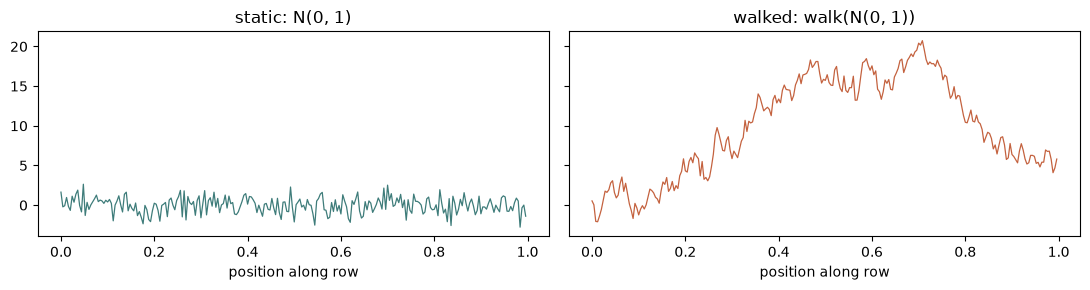

In [6]:
# Demo: one row, same Gaussian steps, with and without the walk operator.
demo = Layer('demo', Rows(ys=[0.5], x0=0.0, x1=1.0, pre={}, advance=0.004 + 0 * U(0, 1)),
             columns={'static': N(0, 1), 'walked': walk(N(0, 1))})
d = evaluate(demo, MASTER, {})
dump(d.t)

fig, axs = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
axs[0].plot(d.t['x'], d.t['static'], color='#3e7c7a', lw=0.9); axs[0].set_title('static: N(0, 1)')
axs[1].plot(d.t['x'], d.t['walked'], color='#c4623f', lw=0.9); axs[1].set_title('walked: walk(N(0, 1))')
for ax in axs: ax.set_xlabel('position along row')
plt.tight_layout(); plt.show()

> **Question.** The left curve has no memory; the right one has nothing *but* memory. Which of the two would make rows that look like rolling water, and why does the range of the right curve keep growing with the number of elements?

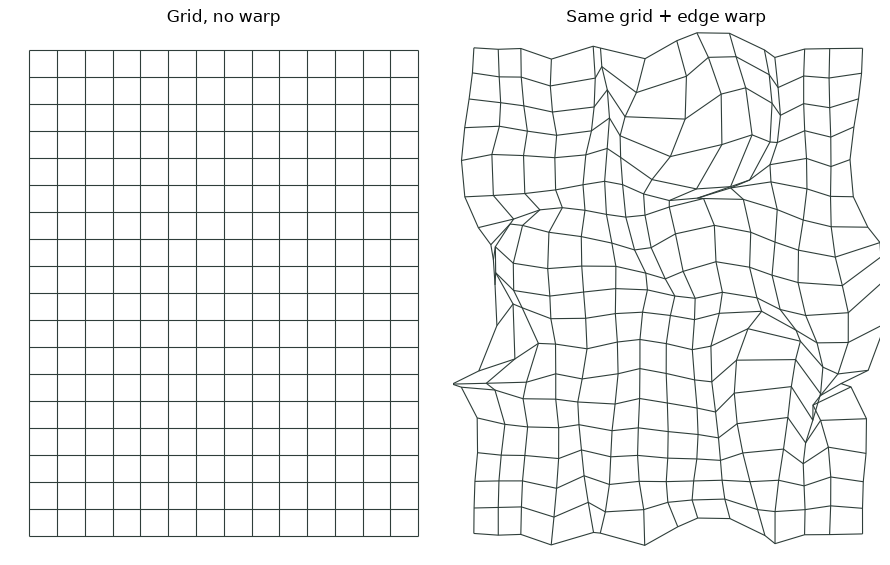

In [7]:
# Structure then break it: the same Grid, with and without warps. Corners move, cells stay joined.
decls = {'form': (28, 160), 'dir': (30, 160)}
fl = make_fields(decls, MASTER)
base = Grid(14, 18, x0=0, x1=1, y0=0, y1=A)
warped = replace(base, warps=(Warp('form', 0.035, 'dir'),))

fig, axs = plt.subplots(1, 2, figsize=(9, 5.8))
for ax, L, title in [(axs[0], base, 'Grid, no warp'), (axs[1], warped, 'Same grid + edge warp')]:
    X, Y = grid_vertices(L, fl)
    segs = [np.column_stack([X[j], Y[j]]) for j in range(X.shape[0])] + \
           [np.column_stack([X[:, i], Y[:, i]]) for i in range(X.shape[1])]
    ax.add_collection(LineCollection(segs, colors='#2f3e3a', linewidths=0.8))
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(A + 0.05, -0.05); ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title)
plt.tight_layout(); plt.show()

> **Question.** Corner $(i,j)$ moves by $\text{amp}\cdot f(x,y)\,(\cos\theta,\sin\theta)$. Neighbouring corners get similar displacements because $f$ is smooth. Why does that keep cells from tearing, and what would happen with white noise instead of a smooth field?

## 5 · Piece 1: shaded arc rows

Acceptance test for layout, shape, shade, palette and accent. Rows overlap; elements start off canvas on the left; spacing is radius times a random factor; colour follows the horizontal position plus a little jitter; **one accent colour** appears on about 1.5 % of the arcs.

The whole drawing is the `Layer` below.

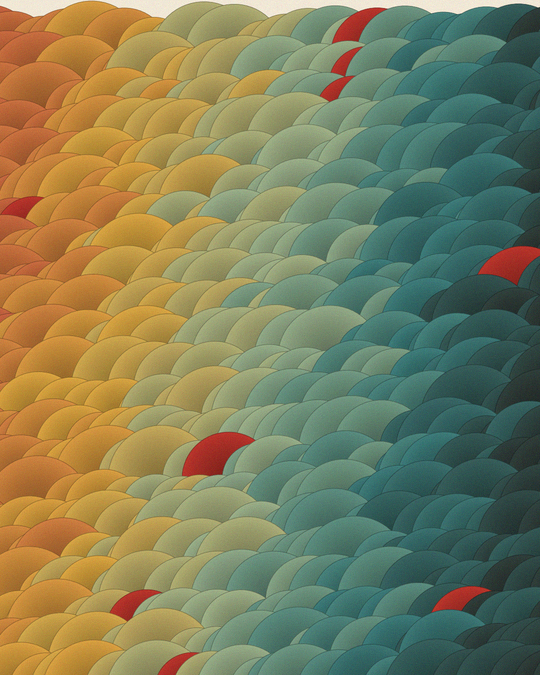

     row |        y |        x |        r |      col |        i |        u |        v |        t
       0 |    0.100 |   -0.100 |    0.061 |        0 |        0 |    0.000 |    0.000 |   -0.114
       0 |    0.100 |   -0.067 |    0.075 |        1 |        1 |    0.028 |    0.000 |   -0.013
       0 |    0.100 |   -0.022 |    0.091 |        2 |        2 |    0.065 |    0.000 |   -0.019
       0 |    0.100 |    0.021 |    0.079 |        3 |        3 |    0.101 |    0.000 |    0.045
       0 |    0.100 |    0.081 |    0.070 |        4 |        4 |    0.151 |    0.000 |    0.118
... 563 elements


In [8]:
EARTH = make_cmap(['#c4623f', '#d9a441', '#9caf88', '#3e7c7a', '#2f3e3a'])

arcs = Layer(
    name='arcs',
    layout=Rows(ys=np.linspace(0.10, A + 0.03, 22), x0=-0.10, x1=1.10,
                pre={'r': U(0.060, 0.100)}, advance=col('r') * U(0.4, 0.8)),
    columns={'t': coord('x') * 0.85 + col('v') * 0.15 + N(0, 0.05)},
    shape=dict(kind='halfdisc', r=col('r')),
    style=dict(fill='fill', stroke=0.35, shade=dict(layers=18, alpha=0.03, spread=0.9, tint=0.35)),
    color=dict(t=col('t'), palette=EARTH, accents=[(choice([0, 1], [0.985, 0.015]), '#b8352b')]),
)

img_arcs, tabs = render([arcs], **QUALITY)
show(img_arcs)
dump(tabs['arcs'])

> **Question.** Look at the layer definition, not the picture. Which single number would you change to make the arcs sit tighter in each row? Which would make the shading deeper? Predict, then change it.

## 6 · Piece 2: the long raging surf

Ten evenly spaced rows. Each circle's height offset is the **walk** of small Gaussian steps, restarting every row, and colour is driven by that same walk value, so *form and colour move together*. Remove the walk and the same drawing becomes static: that is the whole idea, so we test it directly.

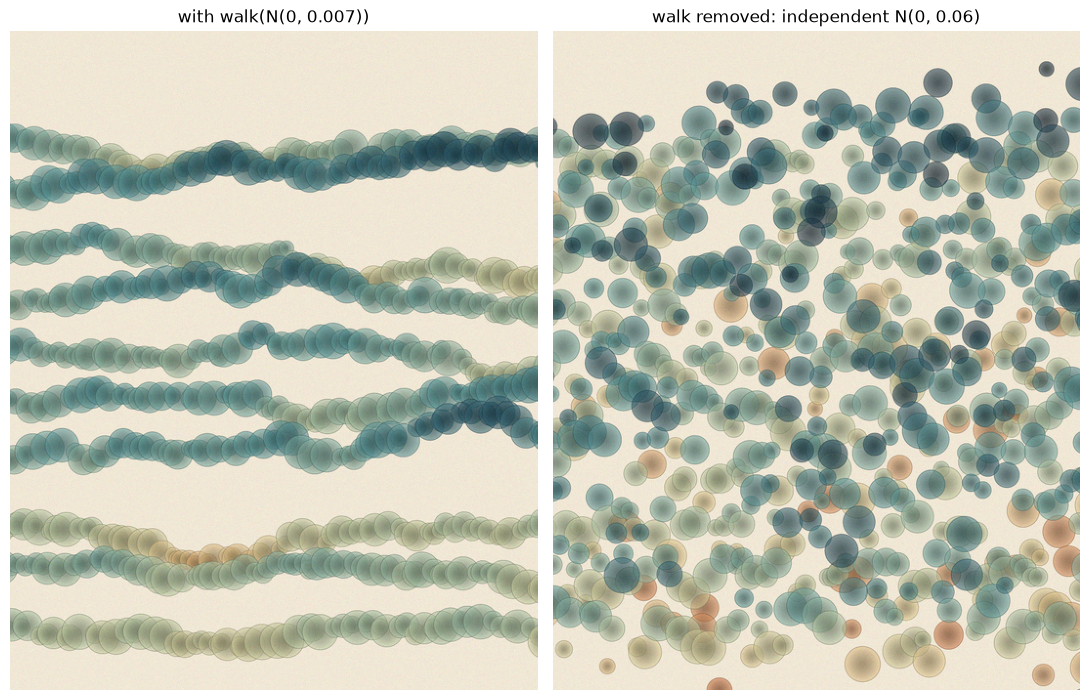

In [9]:
SEA = make_cmap(['#1b2f3f', '#2f5f6f', '#5d9a9b', '#b9c9a4', '#e3c98f', '#c9703f'])

def surf(use_walk=True, name='surf'):
    step = N(0, 0.007)
    dy = walk(step) if use_walk else N(0, 0.06)       # same overall spread, no memory
    return Layer(
        name=name,
        layout=Rows(ys=np.linspace(0.20, A - 0.12, 10), x0=-0.05, x1=1.05,
                    pre={'r': U(0.014, 0.034)}, advance=col('r') * U(0.5, 0.9)),
        columns={'dy': dy, 't': ramp(col('dy'), -0.12, 0.12) * 0.85 + col('v') * 0.15},
        shape=dict(kind='circle', r=col('r'), dy=col('dy')),
        style=dict(fill='fill', alpha=0.55, stroke=0.3, shade=dict(layers=8, alpha=0.05, spread=0.8, tint=0.3)),
        color=dict(t=col('t'), palette=SEA),
    )

img_walk, _   = render([surf(True)],  **QUALITY)
img_static, _ = render([surf(False)], **QUALITY)

fig, axs = plt.subplots(1, 2, figsize=(11, 7))
axs[0].imshow(img_walk);   axs[0].set_title('with walk(N(0, 0.007))')
axs[1].imshow(img_static); axs[1].set_title('walk removed: independent N(0, 0.06)')
for ax in axs: ax.axis('off')
plt.tight_layout(); plt.show()

> **Question.** Both images have the same vertical spread. Why does the left one read as water and the right one as noise? Now try making the walk's step size depend on a field: `walk(N(0, 0.003) + 0.007 * ramp(field('calm'), -2, 2))` (declare a field `'calm'` first) gives drift that is calm in some regions and violent in others, with no new feature.

## 7 · Piece 3: warped grid

Coherence from **one field used in several roles**. The grid corners are displaced by the field `form` (and a finer chained warp). Colour comes from that *same* field, so shape and colour move together. A second field, `wire`, drives stroke width and transparency. Fill state is a `choice`: mostly filled, a few outlines, occasionally nothing.

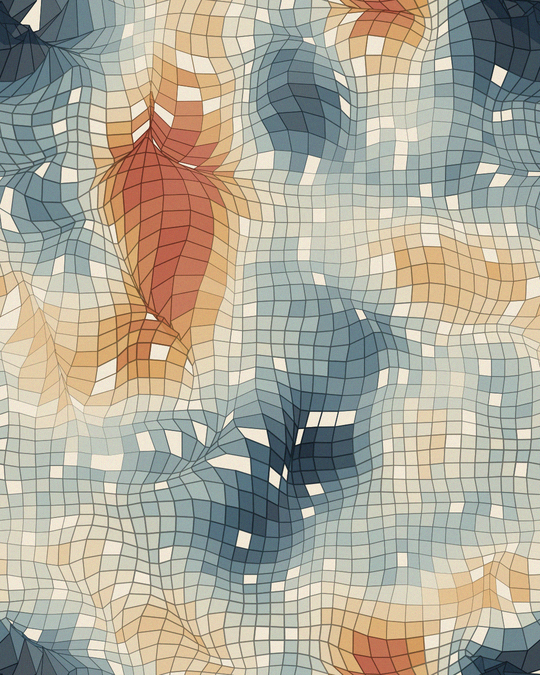

In [10]:
MERC = make_cmap(['#22313f', '#4a6a7a', '#9fb3b0', '#e6dcc3', '#d8a25e', '#b5523b'])
FIELDS = {'form': (16, 200), 'dir': (24, 200), 'wire': (9, 200), 'fine': (6, 200)}

mercury = Layer(
    name='mercury',
    layout=Grid(nx=44, ny=55, x0=-0.06, x1=1.06, y0=-0.06, y1=A + 0.06,
                warps=(Warp('form', 0.020, 'dir'), Warp('fine', 0.004, 'dir'))),
    columns={'t': ramp(field('form'), -2.2, 2.2) + N(0, 0.03),
             'sw': ramp(field('wire'), -2, 2, out=(0.15, 1.1)),
             'al': ramp(field('wire'), -2.5, 2.5, out=(0.70, 1.0))},
    shape=dict(kind='quad'),
    style=dict(fill=choice(['fill', 'outline', 'none'], [0.90, 0.08, 0.02]),
               alpha=col('al'), stroke=col('sw')),
    color=dict(t=col('t'), palette=MERC),
)

img_merc, tabs = render([mercury], fields=FIELDS, **QUALITY)
show(img_merc)

> **Question.** Change `t` from `field('form')` to `field('wire')`. The geometry is identical, but the picture loses something. What? This is the point of one field in several roles.

## 8 · Seeds: isolation and exploration (principle 8)

Two checks, then the workflow.

1. **Isolation.** Adding a column, or wrapping an expression in `scale`/`offset`, must not change draws elsewhere. Wrapping an expression does not add a random operator, so $k$ is unchanged and the draws are identical, merely rescaled.
2. **Exploration.** Vary the master seed to curate, then freeze it and change one parameter at a time. Because of isolation, that behaves as expected.

In [11]:
# 1. Isolation checks (these are assertions, so they double as tests).
fd = make_fields({}, MASTER)
base = evaluate(arcs, MASTER, fd).t

# a) add an unrelated column: nothing else changes
more = evaluate(replace(arcs, columns={**arcs.columns, 'extra': N(0, 1)}), MASTER, fd).t
assert np.array_equal(base['r'], more['r']) and np.array_equal(base['t'], more['t'])

# b) wrap an expression: same draws, rescaled
l1 = Layer('probe', Rows([0.5], 0, 1, pre={}, advance=0.01 + 0 * U(0, 1)), columns={'z': N(0, 1)})
l2 = replace(l1, columns={'z': N(0, 1) * 3 + 5})
z1, z2 = evaluate(l1, MASTER, fd).t['z'], evaluate(l2, MASTER, fd).t['z']
assert np.allclose(z2, 3 * z1 + 5)

# c) a differently named layer draws different numbers
l3 = replace(l1, name='probe2')
assert not np.array_equal(z1, evaluate(l3, MASTER, fd).t['z'])
print('isolation checks passed')

isolation checks passed


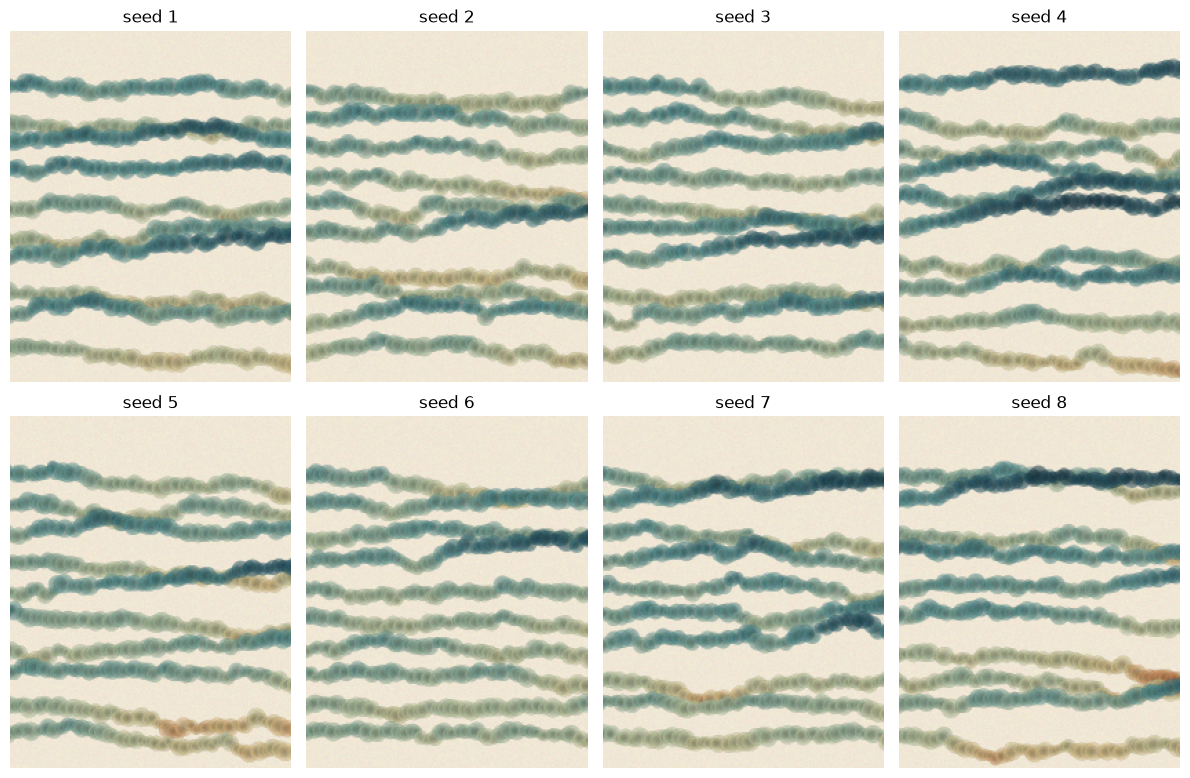

In [12]:
# 2. Contact sheet: vary only the master seed, then pick favourites to freeze.
fig, axs = plt.subplots(2, 4, figsize=(12, 8))
for ax, s in zip(axs.ravel(), range(1, 9)):
    im, _ = render([surf(True)], master=s, dpi=34, ss=1)
    ax.imshow(im); ax.set_title(f'seed {s}'); ax.axis('off')
plt.tight_layout(); plt.show()

## 9 · What this notebook tells us about the design

**Worked.** One engine, three different pieces. Every principle appears as an operator or option, not as a recipe. Seeds are isolated, and the isolation is asserted in code.

**Decisions made while implementing**

* *Seed key.* The spec hashed "the operator's position within the expression". Position changes when you wrap an expression. Here the key is a per-column **counter of random operators**, so wrapping does not matter (check b above).
* *Walks and order.* Walks run in **layout order**; `order` only sorts afterwards, for painting.
* *Grid warp.* Warping corners turns rectangles into quadrilaterals, so the grid needs a `quad` shape. A plain `rect` cannot express it.
* *Shade.* The copies are drawn, because the backend is vector. The closed form $1-(1-a)^k$ is for a later raster backend.

**Not yet in this notebook:** `triangle`, `arc`, `line`, `scatter`/`along_path` layouts, blend modes, YAML round trip, a palette linter. The flow field already exists in the package; a `Lines` shape traced through a field would absorb it.

**Suggested promotion into the package**

| New module | Contents | Test (in the style of `tests/`) |
|---|---|---|
| `math_vis/seeds.py` | `stream` | same key same numbers; different key different |
| `math_vis/expr.py` | `Expr`, operators | `walk` equals `cumsum`; `ramp` clamps; wrapped draws rescale |
| `math_vis/layouts.py` | `Rows`, `Grid`, `Warp` | rows reach `x1`; warped grid keeps shared corners |
| `math_vis/draw.py` | `Layer`, `render` | table dump has standard columns; render is deterministic |

Then this notebook shrinks to imports plus the three `Layer` definitions, in the same spirit as the other demos.